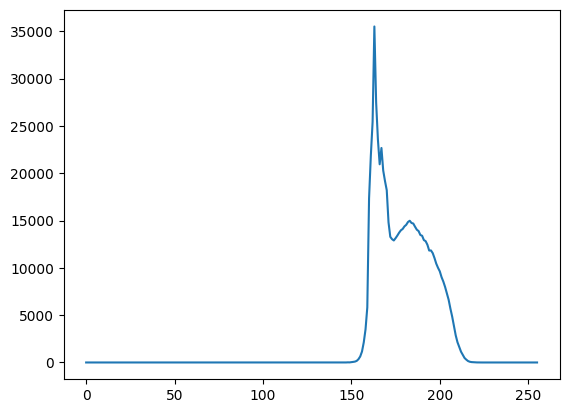

In [ ]:
# Image Histogram

import cv2
import matplotlib.pyplot as plt

image = cv2.imread('lowContrast.jpg', cv2.IMREAD_GRAYSCALE)
hist = cv2.calcHist([image], [0], None, [256], [0, 256])

plt.plot(hist)
plt.savefig('histogram.png')



In [ ]:
# Histogram Equalization

import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread('lowContrast.jpg', cv2.IMREAD_GRAYSCALE)
M, N = image.shape 
pixels = M * N
L = 256 

hist = cv2.calcHist([image], [0], None, [L], [0, L])
hist = hist.flatten()

pr = hist / pixels

sumpr = np.cumsum(pr)
s_k = np.round((L - 1) * sumpr).astype(np.uint8)

equalized_image = s_k[image]
equalized_hist = cv2.calcHist([equalized_image], [0], None, [256], [0, 256])

cv2.imwrite('image.jpg', image)
cv2.imwrite('equalized_image.jpg', equalized_image)


plt.plot(hist)
plt.savefig('original_histogram.png')
plt.close()

plt.plot(equalized_hist)
plt.savefig('equalized_histogram.png')
plt.close()



In [ ]:
# Local Image Enhancement Using Neighborhood Statistics

import cv2
import numpy as np

image = cv2.imread('cube.png', cv2.IMREAD_GRAYSCALE)
image = image.astype(np.float32)

M, N = image.shape
pixels = M * N

hist = cv2.calcHist([image], [0], None, [256], [0, 256])
hist = hist.flatten()

pr = hist / pixels
mG = np.sum(np.arange(256) * pr)
varG = np.sum((np.arange(256) - mG)**2 * pr)

k0, k1 = 0, 1.5
k2, k3 = 0, 2
gain = 3
w = 10 
pad = w // 2

padded = cv2.copyMakeBorder(image, pad, pad, pad, pad, cv2.BORDER_REFLECT)
output = np.copy(image)

for i in range(image.shape[0]):
    for j in range(image.shape[1]):

        window = padded[i:i+w, j:j+w]
        msxy = np.mean(window)
        varsxy = np.var(window)
        
        if (k0 * mG <= msxy <= k1 * mG) and (k2 * varG <= varsxy <= k3 * varG):
            output[i, j] = gain * image[i, j]


output = np.clip(output, 0, 255).astype(np.uint8)

cv2.imwrite('enhanced_cube.png', output)


True

In [ ]:
# 4-Bit Image Quantization, Quantization Error, and Histogram Equalization

from PIL import Image
import numpy as np
import cv2
import matplotlib.pyplot as plt

def PictureProcess(image_path):
    img = Image.open(image_path).convert('L')
    imgAr = np.array(img)

    newPixels = (imgAr // 16) * 17

    new_img = Image.fromarray(newPixels.astype(np.uint8))
    new_img.save("4_bits_plane.png")

    image_subtracted = cv2.absdiff(imgAr, newPixels)
    image_subtracted_pil = Image.fromarray(image_subtracted)
    image_subtracted_pil.save("new_4_bits_subtracted.png")

    pixels = imgAr.size
    hist = cv2.calcHist([imgAr], [0], None, [256], [0, 256]).flatten()

    pr = hist / pixels
    sumpr = np.cumsum(pr)
    s_k = np.round(255 * sumpr).astype(np.uint8)

    equalized_image = s_k[imgAr]
    equalized_hist = cv2.calcHist(
        [equalized_image], [0], None, [256], [0, 256]
    )

    plt.plot(hist)
    plt.title("Original Histogram")
    plt.savefig('original4bitHistogram.png')
    plt.close()

    cv2.imwrite('equalized_4bitimage.jpg', equalized_image)

    plt.plot(equalized_hist)
    plt.title("Equalized Histogram")
    plt.savefig('equalized4bitHistogram.png')
    plt.close()

PictureProcess("pic.jpg")